   Experience  Salary
0           1   25000
1           2   30000
2           3   36000
3           4   42000
4           5   50000
5           6   60000
6           7   72000
7           8   85000
8           9   98000
9          10  115000

Model Performance
------------------------------
MAE : 7219.918240830295
MSE : 68843266.38994718
RMSE: 8297.184244666812
R2 Score: 0.9404470013927793

Prediction Comparison
   Actual     Predicted
0   98000  94868.608020
1   30000  41308.444502


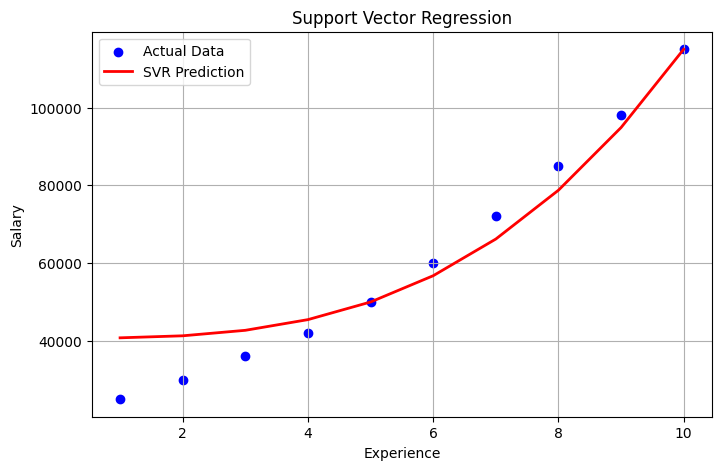

In [3]:
# ==========================
# Import Libraries
# ==========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================
# Create Dataset
# ==========================

df = pd.DataFrame({
    "Experience": [1,2,3,4,5,6,7,8,9,10],
    "Salary": [25000,30000,36000,42000,50000,
               60000,72000,85000,98000,115000]
})

print(df)

# ==========================
# Features & Target
# ==========================

X = df[["Experience"]]
y = df["Salary"]

# ==========================
# Train Test Split
# ==========================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ==========================
# Create SVR Model
# ==========================

model = SVR(
    kernel="poly",
    C=100,
    epsilon=0.1,
    gamma="scale"
)

# ==========================
# Train Model
# ==========================

model.fit(X_train, y_train)

# ==========================
# Prediction
# ==========================

y_pred = model.predict(X_test)

# ==========================
# Evaluation
# ==========================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Performance")
print("-" * 30)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# ==========================
# Actual vs Predicted
# ==========================

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nPrediction Comparison")
print(result)

# ==========================
# Visualization
# ==========================

plt.figure(figsize=(8,5))

plt.scatter(
    X,
    y,
    color="blue",
    label="Actual Data"
)

plt.plot(
    X,
    model.predict(X),
    color="red",
    linewidth=2,
    label="SVR Prediction"
)

plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Support Vector Regression")

plt.legend()
plt.grid(True)

plt.show()